# Precursor frequency, probability mass and expected cells

Compare complete human TRB reference sets for GILGFVFTL, NLVPMVATV and LLWNGPMAV. Calculate their probability mass through the published `precursor` CLI, then separate model frequency, expected cells and occupancy.

**Before you start**

Install `vdjmatch[bench,precursor,notebook]` and `ipykernel`. Open from the repository root or the complete `examples` directory. Set `AIRR_BENCHMARK` if your mirror is elsewhere (default: `~/hf/airr_benchmark`).

## 1. Define the model assumptions

Use a marginal TRB recombination model, radius 1, cognacy retention 0.1 per edit and the existing selection multiplier 9.41. These constants are explicit assumptions, not fits to the plotted epitopes. Expected cells use a 10¹¹-cell pool and compartment fraction 0.3.

In [ ]:
# Set budgets before numerical imports; every calculation uses a fresh CLI output directory.
import os, sys, json, tempfile, platform, subprocess, hashlib
from pathlib import Path
from importlib.metadata import version
THREADS = 4
for key in ("POLARS_MAX_THREADS", "OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ[key] = "1"
os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir())/"vdjmatch-matplotlib"))
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import psutil
examples = next(p for p in (Path.cwd()/"examples", Path.cwd()) if (p/"profile_cli.py").is_file())
sys.path.insert(0, str(examples))
from profile_cli import profile
output = Path(tempfile.mkdtemp(prefix="vdjmatch-scientific-example-"))
benchmark = Path(os.environ.get("AIRR_BENCHMARK", Path.home()/"hf/airr_benchmark"))
reference = benchmark/"vdjdb/vdjdb-2026-06-11-ZENODO/vdjdb_full.txt.gz"
if not reference.is_file():
    raise FileNotFoundError("Set AIRR_BENCHMARK to the complete local benchmark mirror")
print("Python", platform.python_version(), platform.machine())
for package in ("vdjmatch", "vdjtools", "seqtree", "polars", "matplotlib", "scikit-learn", "psutil"):
    print(package, version(package))
print("Logical CPUs:", psutil.cpu_count(), "physical cores:", psutil.cpu_count(logical=False),
      "RAM (GB):", round(psutil.virtual_memory().total/1e9, 1))
print("Fresh output directory:", output)
print("Reference SHA256:", hashlib.sha256(reference.read_bytes()).hexdigest())
# Consistent final-size typography and colour-blind-safe scientific encodings.
plt.rcParams.update({"font.family":"DejaVu Sans", "font.size":8, "axes.labelsize":8,
                    "axes.titlesize":9, "legend.fontsize":7, "xtick.labelsize":7,
                    "ytick.labelsize":7, "axes.spines.top":False, "axes.spines.right":False,
                    "pdf.fonttype":42, "svg.fonttype":"none", "figure.dpi":150})
COLORS = ["#0072B2", "#D55E00", "#009E73", "#CC79A7"]
def export(fig, name):
    for extension in ("pdf", "svg", "png"):
        fig.savefig(output/f"{name}.{extension}", dpi=300, bbox_inches="tight")


## 2. Load complete reference sets

Keep independent source records; the CLI deduplicates junction search keys. Legacy VDJdb `cdr3` contains conserved anchors and therefore represents a junction. These peptide-level marginal estimates pool MHC restrictions explicitly; retain MHC metadata in the input table.

In [ ]:
# Read the pinned reference and export all target source observations for the precursor CLI.
from vdjmatch import db
EPITOPES=["GILGFVFTL","NLVPMVATV","LLWNGPMAV"]
reference_rows=db.load(reference,species="HomoSapiens",gene="TRB")
cognate=reference_rows.filter(pl.col("epitope").is_in(EPITOPES))
assert set(cognate["epitope"].unique())==set(EPITOPES)
cognate.write_csv(output/"cognate-source.tsv",separator="\t")
counts=cognate.group_by("epitope").agg(pl.len().alias("source_records"),
          pl.col("cdr3").n_unique().alias("distinct_junctions"),
          pl.col("reference_id").n_unique().alias("distinct_reference_ids")).sort("epitope")
print(counts)


shape: (3, 4)
┌───────────┬────────────────┬────────────────────┬────────────────────────┐
│ epitope   ┆ source_records ┆ distinct_junctions ┆ distinct_reference_ids │
│ ---       ┆ ---            ┆ ---                ┆ ---                    │
│ str       ┆ u32            ┆ u32                ┆ u32                    │
╞═══════════╪════════════════╪════════════════════╪════════════════════════╡
│ GILGFVFTL ┆ 12798          ┆ 6637               ┆ 30                     │
│ LLWNGPMAV ┆ 2239           ┆ 2143               ┆ 8                      │
│ NLVPMVATV ┆ 19125          ┆ 13391              ┆ 57                     │
└───────────┴────────────────┴────────────────────┴────────────────────────┘


## 3. Calculate neighbourhood mass

The union estimator counts mass once where one-substitution neighbourhoods overlap. Cognacy retention discounts the added shell. The CLI writes one fresh flat TSV; `--no-unseen` keeps this lesson focused on observed sets and neighbourhood mass.

In [ ]:
# Run the established estimator with explicit assumptions and measure the complete process tree.
command=[sys.executable,"-m","vdjmatch.cli","precursor",str(output/"cognate-source.tsv"),
         "--junction-col","cdr3","--group-by","epitope","--locus","TRB",
         "--source","olga","--organism","human","--radius","1","--alpha","0.1",
         "--q","9.41","--n-cells","1e11","--compartment","0.3","--n-eff","1e8",
         "--no-unseen","--threads",str(THREADS),"--output",str(output/"precursor.tsv")]
usage=profile(command,output/"precursor.log",timeout=300)
estimates=pl.read_csv(output/"precursor.tsv",separator="\t").rename({"group":"epitope"}).sort("epitope")
print(estimates)
print("Elapsed seconds:",round(usage["seconds"],2),"peak tree GB:",round(usage["peak_tree_rss_GB"],3))


## 4. Check the estimates

Verify that observed mass ≤ retained mass ≤ unweighted union ≤ naive sum. Keep source-record and distinct-junction counts beside the estimates.

In [ ]:
# Inspect the authoritative columns and retain exact counts beside all estimates.
print(estimates.columns)
assert estimates.height==len(EPITOPES)
combined=counts.join(estimates,on="epitope",validate="1:1")
combined.write_csv(output/"precursor-with-counts.tsv",separator="\t")

assert (estimates["observed_mass"] <= estimates["retained"]).all()
assert (estimates["retained"] <= estimates["union"]).all()
assert (estimates["union"] <= estimates["naive_sum"] * (1 + 1e-10)).all()


## 5. Compare frequency and expected cells

Both panels use the same epitope order and logarithmic axes. Expected cells are the model frequency multiplied by 10¹¹ × 0.3, an explicit unit conversion rather than independent validation.

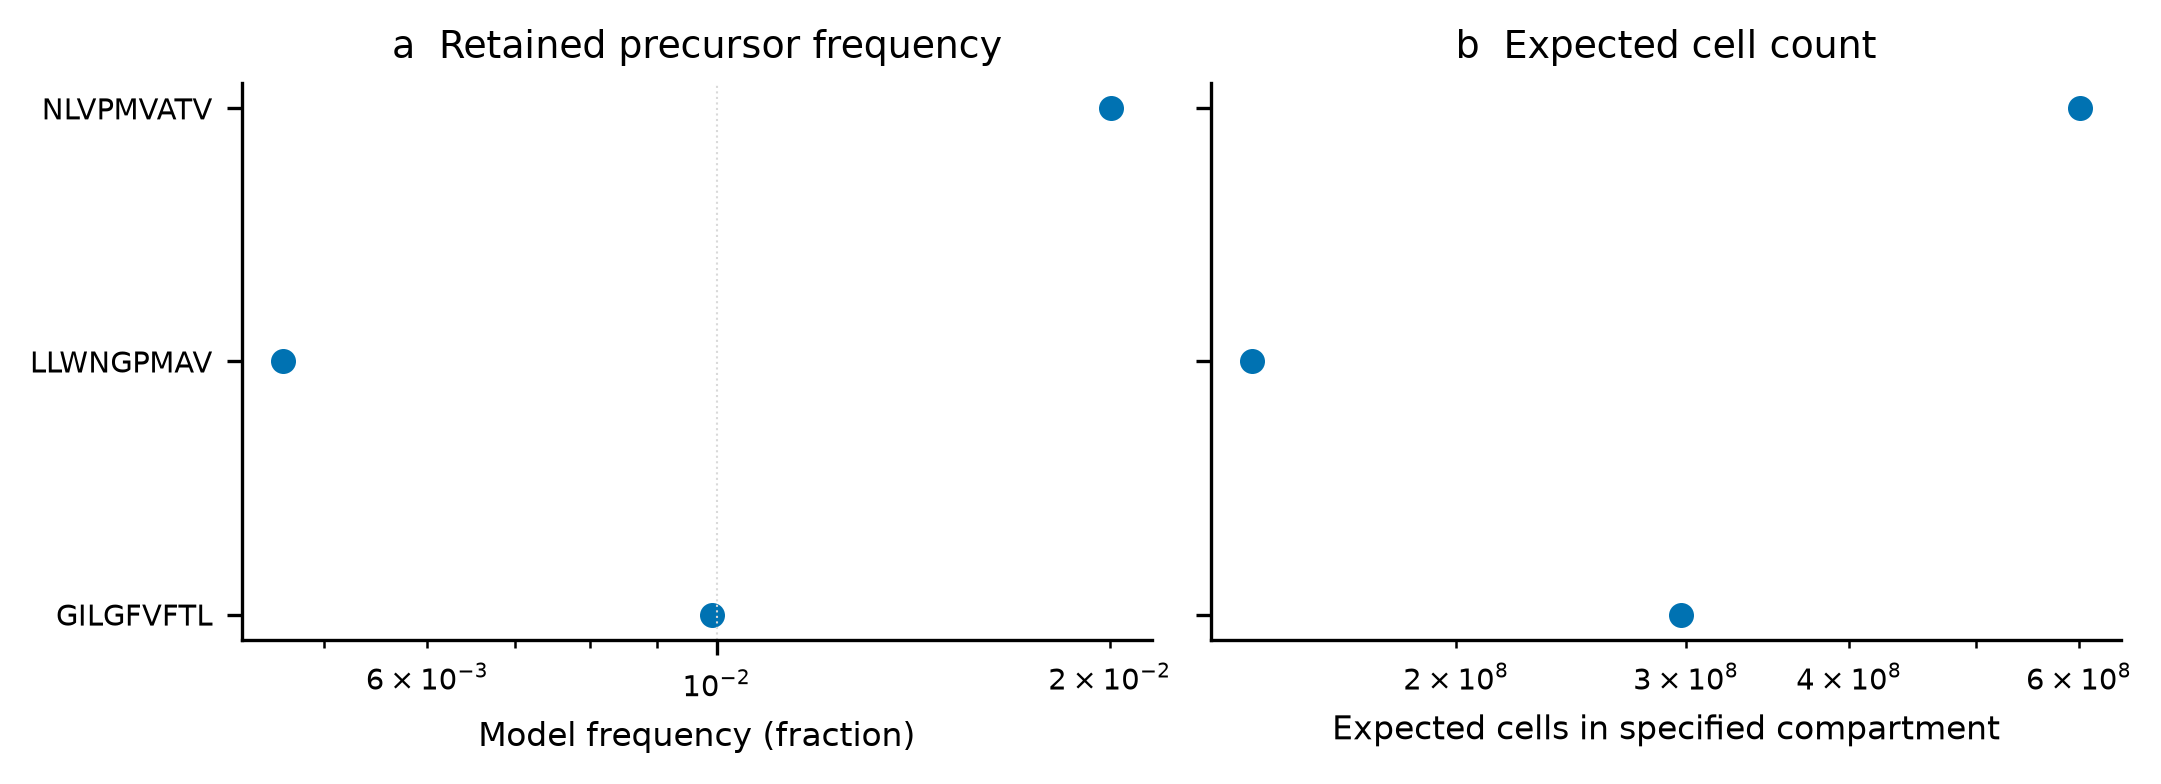

In [ ]:
# Plot frequency and expected cells directly from the CLI output, with a common epitope order.
labels=combined["epitope"].to_list(); y=np.arange(len(labels))
fig,axes=plt.subplots(1,2,figsize=(7.09,2.5),sharey=True,layout="constrained")
for ax,col,label,title in zip(axes,["F","cells"],["Model frequency (fraction)","Expected cells in specified compartment"],
                            ["a  Retained precursor frequency","b  Expected cell count"]):
    ax.scatter(combined[col],y,color="#0072B2",s=25)
    ax.set(xscale="log",xlabel=label,title=title)
    ax.set_yticks(y,labels)
    ax.grid(axis="x",ls=":",lw=.5,color="0.85")
export(fig,"precursor-frequency-cells");plt.show()


**Figure 1 | Marginal TRB precursor estimates under explicit model assumptions.** **a**, Model frequency for the complete cognate junction sets of three peptides, calculated with radius 1, per-edit retention 0.1 and selection multiplier 9.41. **b**, Expected cells after multiplying each frequency by 10¹¹ × 0.3. Points are deterministic model estimates; no empirical uncertainty interval or significance test is introduced. Source-record, distinct-junction and reference-ID counts accompany the flat table; distinct source IDs need not represent independent assays.

## 6. Separate observed and added mass

Observed junctions provide a lower bound. Cognacy retention discounts the added shell; the unweighted union includes its full probability. The three marks distinguish these quantities directly.

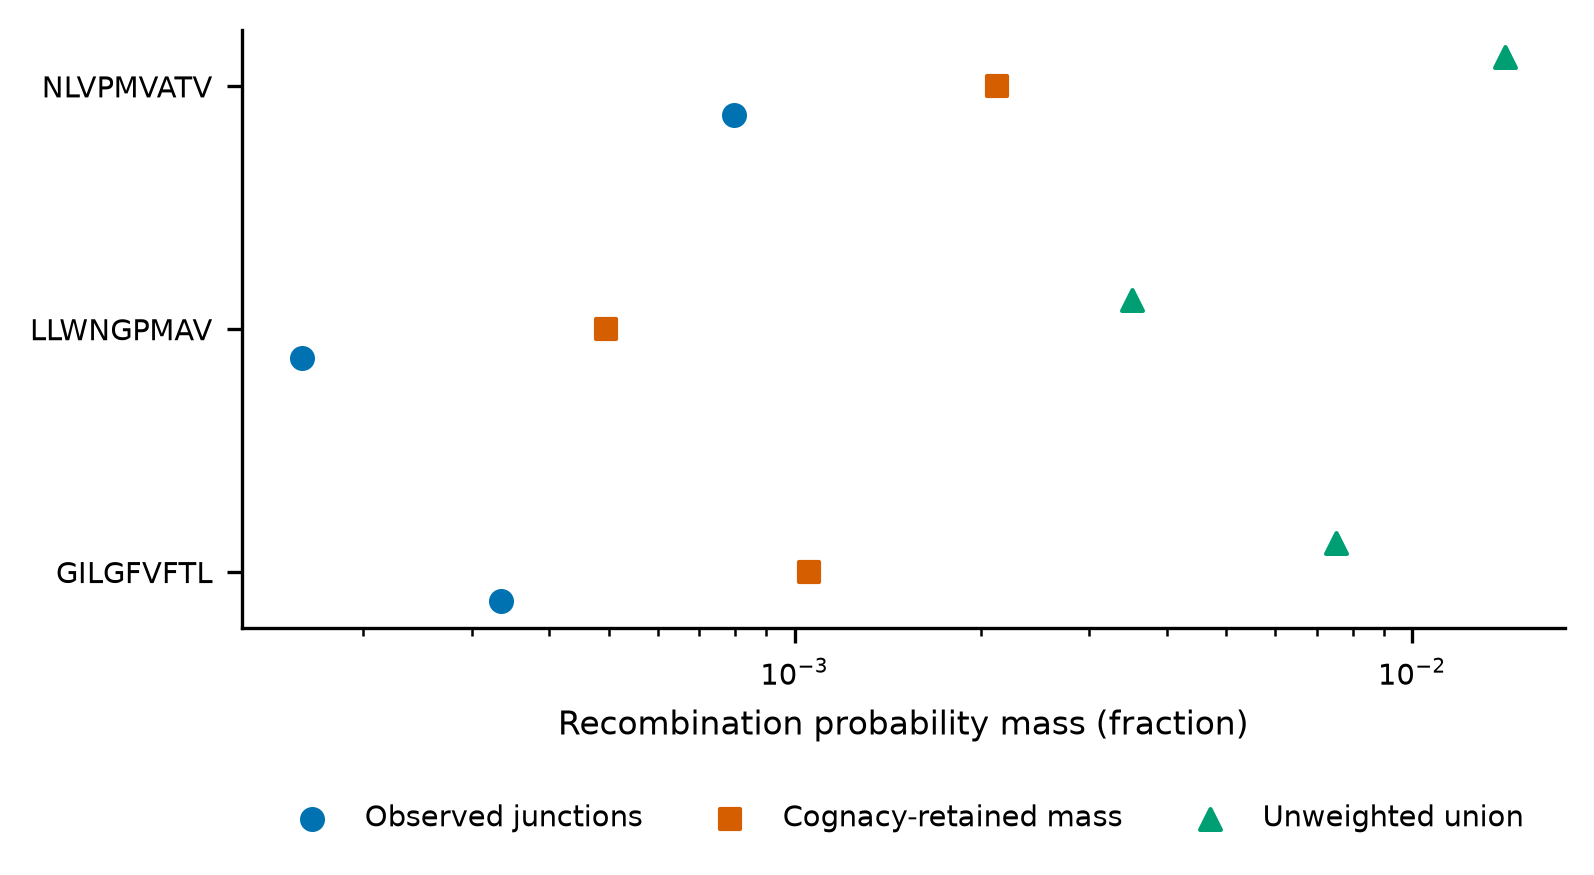

In [ ]:
# Compare the CLI's observed, retained and unweighted union masses on a common log axis.
fig,ax=plt.subplots(figsize=(5.2,2.8),layout="constrained")
for i,(col,label,color,marker) in enumerate([("observed_mass","Observed junctions","#0072B2","o"),
    ("retained","Cognacy-retained mass","#D55E00","s"),("union","Unweighted union","#009E73","^")]):
    ax.scatter(combined[col],y+(i-1)*.12,color=color,marker=marker,s=25,label=label)
ax.set(yticks=y,yticklabels=labels,xscale="log",xlabel="Recombination probability mass (fraction)")
ax.legend(frameon=False,loc="upper center",bbox_to_anchor=(.5,-.25),ncol=3)
export(fig,"precursor-mass-decomposition");plt.show()
# Occupancy is saturated for these sets at the specified rearrangement count; keep exact values in a table.
print(combined.select("epitope","lambda","p_ge_1","p_ge_10"))


**Figure 2 | Observed and added neighbourhood mass.** Circles, squares and triangles identify the observed-junction mass, cognacy-retained mass and unweighted union, respectively. All are fractions under the same marginal TRB recombination model and complete reference sets. The retained value lies between the observed set and the radius-1 union. Marker separation reflects the explicitly assumed shell-retention weight; it is not an uncertainty interval.

At the assumed 10⁸ independent rearrangements, the CLI reports the Poisson mean and the probability of at least one or ten precursors in the accompanying table. Near-one occupancy means model-supported precursors are expected to exist at that repertoire size; it is not a probability of mounting a detectable immune response.

## 7. Export resource measurements

In [ ]:
# Save whole-invocation measurements with complete source-record and junction counts.
pl.DataFrame([{"workflow":"Three complete TRB precursor sets","source_records":cognate.height,
               "native_threads":THREADS,**usage}]).write_csv(output/"resources.tsv",separator="\t")
print({k:round(v,3) if isinstance(v,float) else v for k,v in usage.items()})


## Interpretation and limits

The calculation separates neighbourhood mass → retained mass → assumed selected frequency → expected cells → occupancy.

- Reference-set sizes differ and influence neighbourhood mass.
- The model is marginal human TRB. MHC restrictions are pooled explicitly; it is not a paired binding model.
- Selection, retention and pool parameters are assumptions. The estimates are deterministic; no empirical uncertainty or response probability is inferred.
- Measured precursor frequencies in the literature compendium are validation observations, not substitutes for these model estimates.

Fresh CLI TSVs and editable PDF/SVG plus 300-dpi PNG figures are in the output directory.